# Predicción de la calidad del vino blanco
El objetivo de este proyecto es desarrollar modelos de Machine Learning que permitan predecir la calidad del vino blanco a partir de sus propiedades fisicoquímicas. Se decidió trabajar únicamente con la variedad de vino blanco porque el conjunto de datos disponible contiene una mayor cantidad de registros que el de vino tinto. Para realizar el análisis se utilizará el conjunto de datos Wine Quality, que contiene información sobre distintas características del vino y una variable que representa su calidad.

## 1. Importación de librerías
Se importan las bibliotecas necesarias para trabajar con los datos, realizar cálculos y generar gráficos durante el análisis exploratorio.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carga del conjunto de datos
Se carga el archivo CSV correspondiente al conjunto de datos, que contiene información sobre las propiedades fisicoquímicas del vino blanco y su calidad.

In [24]:
data = pd.read_csv("Desktop/winequality-white.csv", sep=";")

In [25]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 3. Inspección inicial de los datos
Se realiza una primera revisión del conjunto de datos para conocer su tamaño, las variables disponibles, los tipos de datos y la existencia de valores faltantes o registros duplicados.

In [26]:
#DIMENSION
print(data.shape)

(4898, 12)


In [27]:
# NOMBRES DE COLUMNAS
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [28]:
#TIPO DE DATOS
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   str    
 11  quality               4898 non-null   int64  
dtypes: float64(10), int64(1), str(1)
memory usage: 475.8 KB


In [29]:
#VALORES FALTANTES
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [30]:
# REGISTROS DUPLICADOS
data.duplicated().sum()

np.int64(937)

Se detectaron 937 registros duplicados en el conjunto de datos original. Estos registros serán evaluados durante la etapa de limpieza para evitar que las observaciones repetidas tengan un peso mayor en el análisis y en el entrenamiento de los modelos.

## 4. Limpieza y corrección de datos

En esta etapa se revisan y corrigen algunos valores del conjunto de datos que presentan inconsistencias. También se eliminan los registros duplicados para preparar la información antes del análisis exploratorio.

### 4.1. Revisión y corrección de la columna alcohol

Se revisó la columna `alcohol` para comprobar su tipo de dato y detectar valores que no tenían un formato numérico correcto. Durante esta revisión se encontraron algunos registros inconsistentes que debieron corregirse utilizando los datos originales del conjunto Wine Quality.

In [31]:
print(data["alcohol"].head(10))
print(data["alcohol"].dtype)

0     8.8
1     9.5
2    10.1
3     9.9
4     9.9
5    10.1
6     9.6
7     8.8
8     9.5
9      11
Name: alcohol, dtype: str
str


In [32]:
print(data["alcohol"].unique()[:20])

<ArrowStringArray>
[ '8.8',  '9.5', '10.1',  '9.9',  '9.6',   '11',   '12',  '9.7', '10.8',
 '12.4', '11.4', '12.8', '11.3', '10.5',  '9.3',   '10', '10.4', '11.6',
 '12.3', '10.2']
Length: 20, dtype: str


In [33]:
data["alcohol"] = pd.to_numeric(data["alcohol"])

ValueError: Unable to parse string "128.933.333.333.333" at position 4315

In [34]:
alcohol_numerico = pd.to_numeric(data["alcohol"], errors="coerce")

valores_invalidos = data[alcohol_numerico.isna()]

print(valores_invalidos[["alcohol", "quality"]])

                  alcohol  quality
4315  128.933.333.333.333        7
4319  128.933.333.333.333        7
4323  114.666.666.666.667        6
4341  100.333.333.333.333        6
4353  114.333.333.333.333        6
4356  105.333.333.333.333        5
4358  953.333.333.333.333        5
4364  109.333.333.333.333        6
4369  109.333.333.333.333        6
4372  113.666.666.666.667        6
4377  113.333.333.333.333        6
4380  110.666.666.666.667        6
4383  113.333.333.333.333        6
4403  973.333.333.333.333        5
4410  973.333.333.333.333        5
4435  113.333.333.333.333        6
4507  123.333.333.333.333        5
4615  112.666.666.666.667        7
4636  105.666.666.666.667        5
4637  117.333.333.333.333        6
4654  109.666.666.666.667        7
4655  109.666.666.666.667        7
4656  109.666.666.666.667        7
4663  101.333.333.333.333        7
4664  101.333.333.333.333        7
4671  104.666.666.666.667        5
4672  104.666.666.666.667        5
4674  116.333.333.33

In [35]:
print("Cantidad de valores problemáticos:", len(valores_invalidos))

print(valores_invalidos["alcohol"].value_counts())

Cantidad de valores problemáticos: 34
alcohol
953.333.333.333.333    3
113.333.333.333.333    3
109.666.666.666.667    3
128.933.333.333.333    2
109.333.333.333.333    2
973.333.333.333.333    2
101.333.333.333.333    2
104.666.666.666.667    2
116.333.333.333.333    2
114.666.666.666.667    1
100.333.333.333.333    1
114.333.333.333.333    1
105.333.333.333.333    1
113.666.666.666.667    1
110.666.666.666.667    1
123.333.333.333.333    1
112.666.666.666.667    1
105.666.666.666.667    1
117.333.333.333.333    1
131.333.333.333.333    1
120.666.666.666.667    1
963.333.333.333.333    1
Name: count, dtype: int64


Se identificaron 34 registros con valores incorrectos en la columna alcohol, que presentaban problemas en su formato numérico e impedían su correcta conversión. Para solucionar esta inconsistencia, se consultó el conjunto de datos original de UCI Wine Quality y se recuperaron los valores correspondientes.

CONSULTA DE DATASET ORIGINAL

Se carga una copia del conjunto de datos original desde el repositorio UCI Machine Learning Repository. Esta versión se utiliza como referencia para comparar y recuperar los valores incorrectos detectados en la columna alcohol.

In [36]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

data_original = pd.read_csv(url, sep=";")

print(data_original.shape)
data_original.head()

(4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [37]:
data["alcohol"] = pd.to_numeric(data["alcohol"], errors="coerce")

In [38]:
data.loc[valores_invalidos.index, "alcohol"] = data_original.loc[valores_invalidos.index, "alcohol"]

Se realizó la conversión de la columna alcohol a formato numérico y se reemplazaron los 34 valores incorrectos por los valores correspondientes del conjunto de datos original.

In [39]:
print("Tipo de dato:", data["alcohol"].dtype)
print("Valores faltantes:", data["alcohol"].isnull().sum())
print("Cantidad de registros:", len(data))

Tipo de dato: float64
Valores faltantes: 0
Cantidad de registros: 4898


### 4.2. Eliminación de registros duplicados

Se detectaron 937 registros duplicados en el conjunto de datos original. Se decidió eliminarlos para evitar que las observaciones idénticas tengan un peso mayor en el análisis. Para ello, se creó un nuevo DataFrame sin duplicados y se comparó la cantidad de registros antes y después de la limpieza.

In [40]:
# Cantidad de registros antes de eliminar duplicados
print("Registros originales:", data.shape[0])

# Crear un nuevo DataFrame sin duplicados
data_sin_duplicados = data.drop_duplicates()

# Cantidad de registros después de eliminar duplicados
print("Registros sin duplicados:", data_sin_duplicados.shape[0])

# Cantidad de duplicados eliminados
print("Duplicados eliminados:", data.shape[0] - data_sin_duplicados.shape[0])

Registros originales: 4898
Registros sin duplicados: 3961
Duplicados eliminados: 937


In [41]:
# Actualizar el dataset sin registros duplicados
data = data_sin_duplicados.copy()

# Verificar los resultados
print("Cantidad de registros:", data.shape[0])
print("Duplicados restantes:", data.duplicated().sum())

Cantidad de registros: 3961
Duplicados restantes: 0


### 4.3 Análisis estadístico descriptivo

Se realiza un análisis estadístico descriptivo para conocer las principales características de las variables numéricas, como la media, la desviación estándar, los valores mínimos y máximos. Esta revisión permite identificar posibles valores inusuales o inconsistencias en los datos.

In [42]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000
mean,6.839346,0.280538,0.334332,5.914819,0.045905,34.889169,137.193512,1.565523,3.195458,0.490351,10.589358,5.854835
std,0.866860,0.103437,0.122446,4.861646,0.023103,17.210021,43.129065,7.077573,0.151546,0.113523,1.217076,0.890683
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.600000,0.035000,23.000000,106.000000,0.991620,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,4.700000,0.042000,33.000000,133.000000,0.993500,3.180000,0.480000,10.400000,6.000000
75%,7.300000,0.330000,0.390000,8.900000,0.050000,45.000000,166.000000,0.995710,3.290000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,103.898000,3.820000,1.080000,14.200000,9.000000


### 4.4. Detección de inconsistencias en la columna density

A partir del análisis estadístico descriptivo, se observaron valores inusualmente elevados en la columna `density`. Para investigar esta situación, se revisan sus valores mínimos y máximos y registros con valores superiores a 2.

In [43]:
print("Densidad mínima:", data["density"].min())
print("Densidad máxima:", data["density"].max())
print("Valores de density mayores que 2:", (data["density"] > 2).sum())

Densidad mínima: 0.98711
Densidad máxima: 103.898
Valores de density mayores que 2: 51


### 4.5. Corrección de la columna density

Estos resultados indicaron una posible inconsistencia en el formato de los dato, para corregirlos, se utilizaron los valores correspondientes del conjunto de datos original de UCI Wine Quality. De esta manera, se reemplazaron los valores incorrectos sin modificar el resto de las observaciones.

In [44]:
# Identificar los registros con valores incorrectos
indices_densidad = data.index[data["density"] > 2]

# Recuperar los valores originales
data.loc[indices_densidad, "density"] = data_original.loc[indices_densidad, "density"]

# Verificar la corrección
print("Valores corregidos:", len(indices_densidad))
print("Densidad mínima:", data["density"].min())
print("Densidad máxima:", data["density"].max())

Valores corregidos: 51
Densidad mínima: 0.98711
Densidad máxima: 1.03898


### 4.6. Verificación final de los datos

Una vez realizadas las correcciones y eliminado los registros duplicados, se verifica nuevamente el conjunto de datos para comprobar que no existan valores faltantes ni duplicados y que las variables tengan los tipos de datos correspondientes.

In [45]:
# Dimensiones finales
print("Dimensiones:", data.shape)

# Tipos de datos
print("\nTipos de datos:")
print(data.dtypes)

# Valores faltantes
print("\nValores faltantes:")
print(data.isnull().sum())

# Registros duplicados
print("\nDuplicados restantes:", data.duplicated().sum())

Dimensiones: (3961, 12)

Tipos de datos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Valores faltantes:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicados restantes: 0


### RESULTADO DE LA LIMPIEZA

Luego de realizar las correcciones y eliminar los registros duplicados, el conjunto de datos quedó conformado por 3961 registros y 12 columnas.
Se verificó que todas las variables tienen el tipo de dato correspondiente, no existen valores faltantes y tampoco quedaron registros duplicados. De esta manera, los datos se encuentran preparados para continuar con el análisis exploratorio.

In [46]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000
mean,6.839346,0.280538,0.334332,5.914819,0.045905,34.889169,137.193512,0.993790,3.195458,0.490351,10.589358,5.854835
std,0.866860,0.103437,0.122446,4.861646,0.023103,17.210021,43.129065,0.002905,0.151546,0.113523,1.217076,0.890683
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.600000,0.035000,23.000000,106.000000,0.991620,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,4.700000,0.042000,33.000000,133.000000,0.993500,3.180000,0.480000,10.400000,6.000000
75%,7.300000,0.330000,0.390000,8.900000,0.050000,45.000000,166.000000,0.995710,3.290000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


## 5. Análisis exploratorio de datos (EDA)

En esta etapa se realiza un análisis exploratorio para conocer la distribución de las variables, identificar posibles valores atípicos y observar las relaciones entre las propiedades fisicoquímicas y la calidad del vino.

### 5.1. Distribución de la calidad del vino

Se analiza la cantidad de registros correspondientes a cada nivel de calidad para conocer cómo se distribuyen las observaciones dentro del conjunto de datos.

quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64


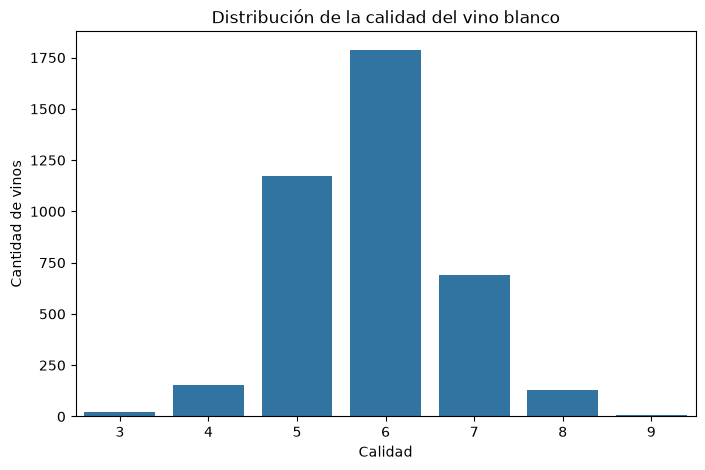

In [47]:
# Cantidad de vinos por nivel de calidad
print(data["quality"].value_counts().sort_index())

# Gráfico de distribución de la calidad
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="quality")

plt.title("Distribución de la calidad del vino blanco")
plt.xlabel("Calidad")
plt.ylabel("Cantidad de vinos")
plt.show()

In [48]:
# Porcentaje de vinos por nivel de calidad
porcentajes = data["quality"].value_counts(normalize=True).sort_index() * 100

print(porcentajes.round(2))

quality
3     0.50
4     3.86
5    29.66
6    45.14
7    17.39
8     3.31
9     0.13
Name: proportion, dtype: float64


**Interpretación:**

La distribución de la variable `quality` muestra que la mayor cantidad de vinos se concentra en los niveles de calidad 5 y 6, que representan el 29,66 % y el 45,14 % del total, respectivamente. En menor proporción aparecen los vinos con calidad 7 (17,39 %).

Por otro lado, las categorías 3, 4, 8 y 9 presentan una cantidad reducida de observaciones. Esto evidencia un desbalance en la distribución de la variable objetivo, ya que algunas categorías tienen una representación mucho mayor que otras.

### 5.2. Distribución de las variables fisicoquímicas

Se utilizan histogramas para observar la distribución de las variables numéricas del conjunto de datos. Esto permite identificar los rangos de valores más frecuentes y reconocer posibles asimetrías en su distribución.

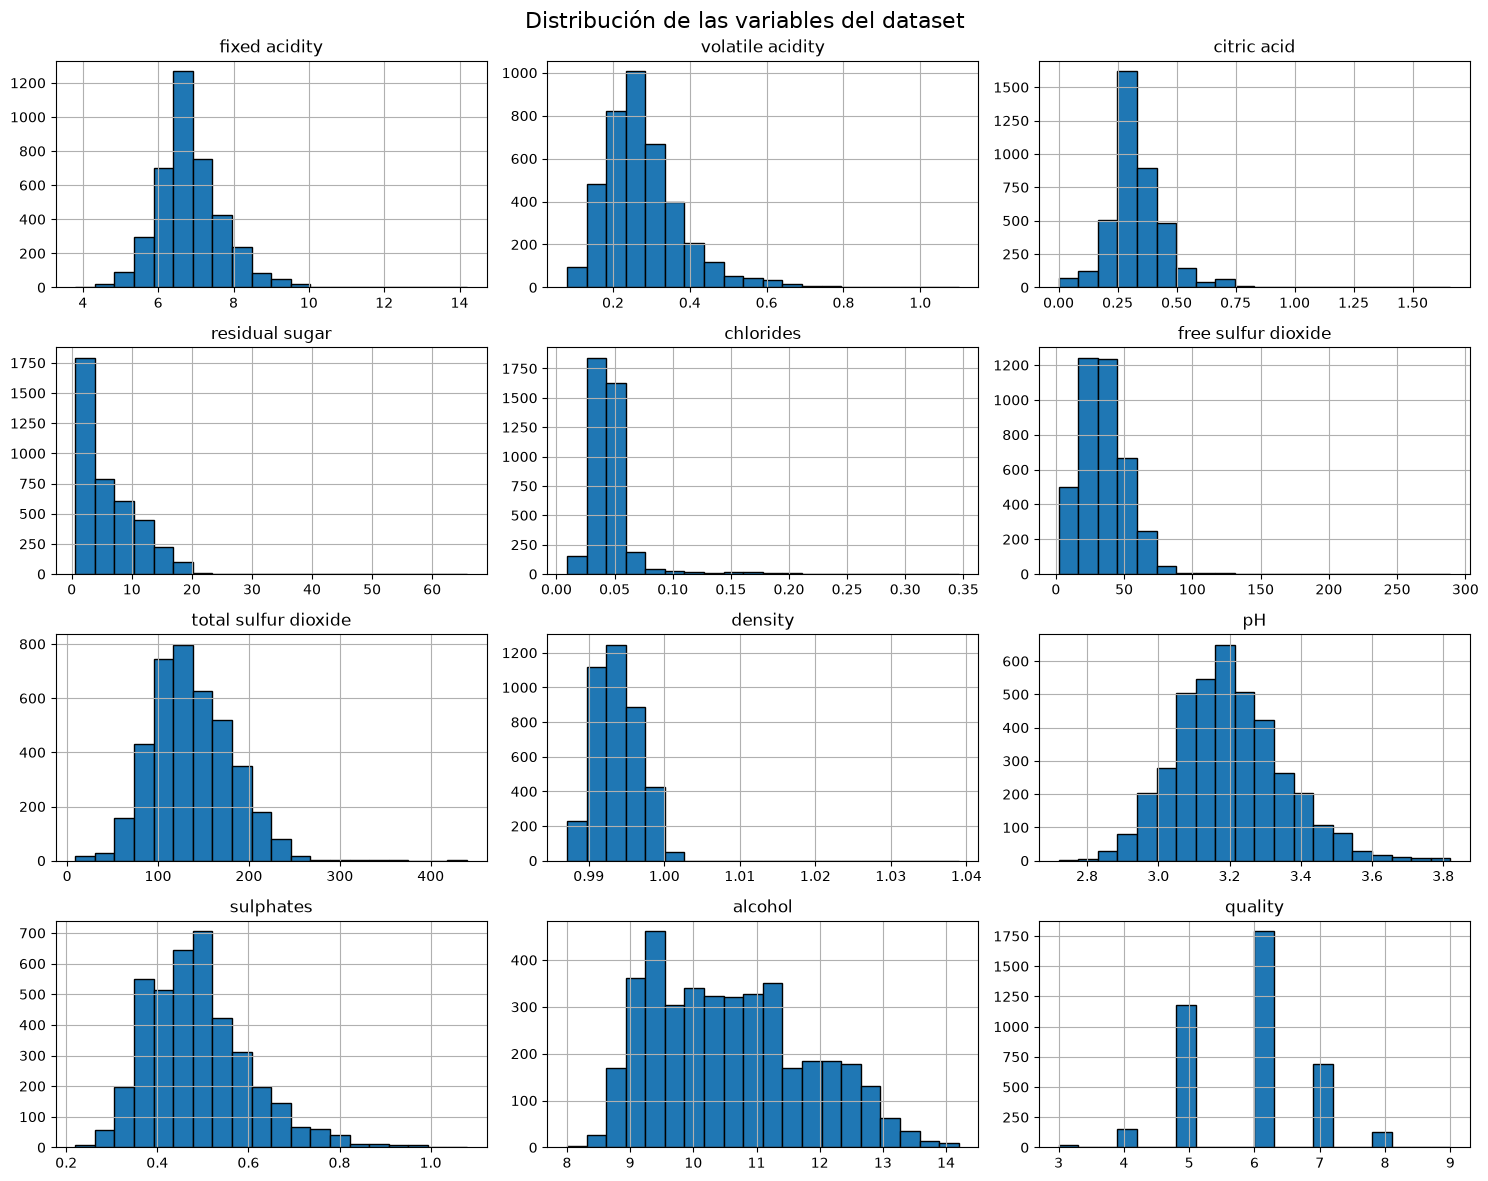

In [49]:
# Histogramas de las variables fisicoquímicas
data.hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.suptitle("Distribución de las variables del dataset", fontsize=16)
plt.tight_layout()
plt.show()

In [50]:
# Calcular la asimetría de las variables
data.skew().sort_values(ascending=False)

chlorides               4.969076
volatile acidity        1.641081
free sulfur dioxide     1.566680
residual sugar          1.333639
citric acid             1.310601
density                 1.273318
sulphates               0.937853
fixed acidity           0.696100
total sulfur dioxide    0.456800
pH                      0.455457
alcohol                 0.450697
quality                 0.112004
dtype: float64

**Interpretación de la asimetría:**

El análisis muestra que las variables presentan diferentes grados de asimetría positiva. Se destacan `chlorides`, `volatile acidity`, `free sulfur dioxide`, `residual sugar`, `citric acid` y `density`, cuyos valores indican una mayor concentración de observaciones en los rangos inferiores y la presencia de una cola hacia los valores más elevados.
Por otro lado, variables como `alcohol`, `pH` y `total sulfur dioxide` presentan una asimetría más leve.
Estos resultados permiten conocer mejor el comportamiento de las variables.

### 5.3. Detección de valores atípicos

Se utilizan diagramas de caja para identificar posibles valores atípicos en las variables fisicoquímicas. Estos gráficos permiten observar la dispersión de los datos, los valores centrales y las observaciones que se encuentran alejadas del rango habitual.

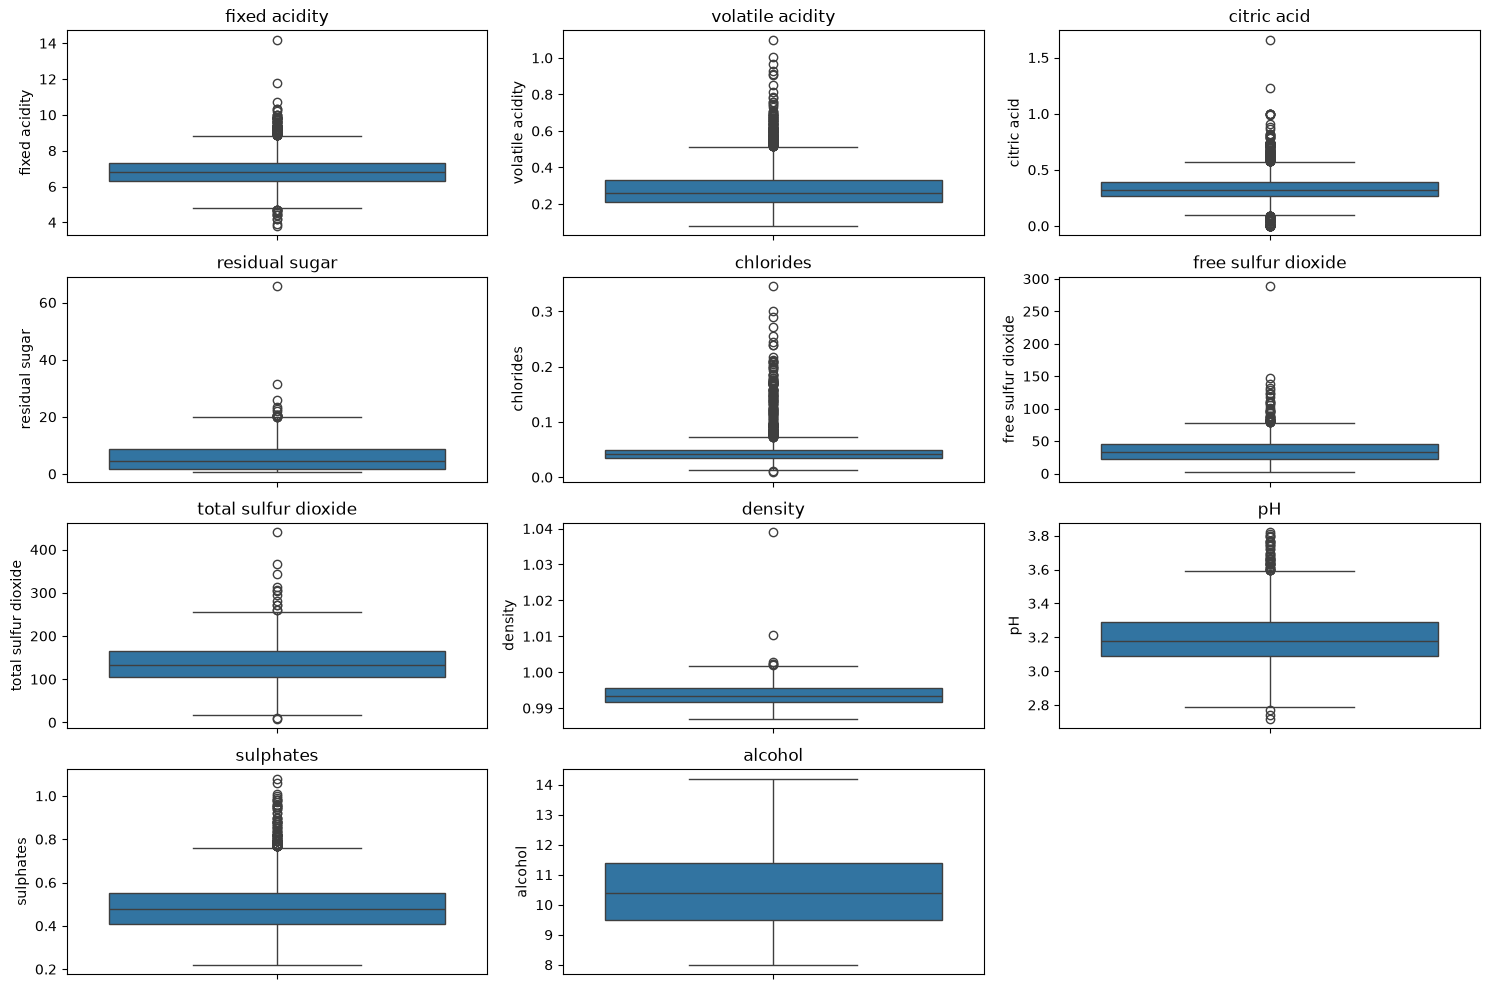

In [51]:
columnas = data.drop(columns=["quality"]).columns

plt.figure(figsize=(15, 10))

for i, columna in enumerate(columnas, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=data[columna])
    plt.title(columna)

plt.tight_layout()
plt.show()

**Observación inicial:**

En los diagramas de caja se identifican numerosos puntos por fuera de los bigotes, lo que indica la posible presencia de valores atípicos en distintas variables fisicoquímicas.
Sin embargo, estos valores no necesariamente representan errores en los datos, ya que pueden corresponder a características reales de algunas muestras de vino. Por esto, se realizará un análisis cuantitativo para identificar y contabilizar los posibles valores atípicos antes de decidir cómo tratarlos.

In [52]:
# Identificar valores atípicos mediante el método IQR

for columna in data.drop(columns="quality").columns:
    Q1 = data[columna].quantile(0.25)
    Q3 = data[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = data[
        (data[columna] < limite_inferior) |
        (data[columna] > limite_superior)
    ]

    print(columna, ":", len(outliers), "valores atípicos")

fixed acidity : 106 valores atípicos
volatile acidity : 133 valores atípicos
citric acid : 223 valores atípicos
residual sugar : 16 valores atípicos
chlorides : 178 valores atípicos
free sulfur dioxide : 44 valores atípicos
total sulfur dioxide : 14 valores atípicos
density : 6 valores atípicos
pH : 46 valores atípicos
sulphates : 96 valores atípicos
alcohol : 0 valores atípicos


**Interpretación de los valores atípicos:**

Mediante el método del rango intercuartílico (IQR), se identificaron posibles valores atípicos en varias variables fisicoquímicas.
La variable `citric acid` presentó la mayor cantidad de observaciones atípicas (223), seguida de `chlorides` (178) y `volatile acidity` (133). En cambio, la variable `alcohol` no presentó valores atípicos según este criterio.
La presencia de estos valores no implica necesariamente que sean errores, ya que pueden representar características reales de determinadas muestras de vino. Por este motivo, se conservarán inicialmente los registros y se tendrá en cuenta su comportamiento durante la preparación de los datos y el entrenamiento de los modelos.

### 5.4. Análisis de correlación entre las variables

Se analiza la correlación entre las variables numéricas mediante una matriz de correlación. Este análisis permite identificar relaciones positivas y negativas entre las propiedades fisicoquímicas y la variable objetivo `quality`.

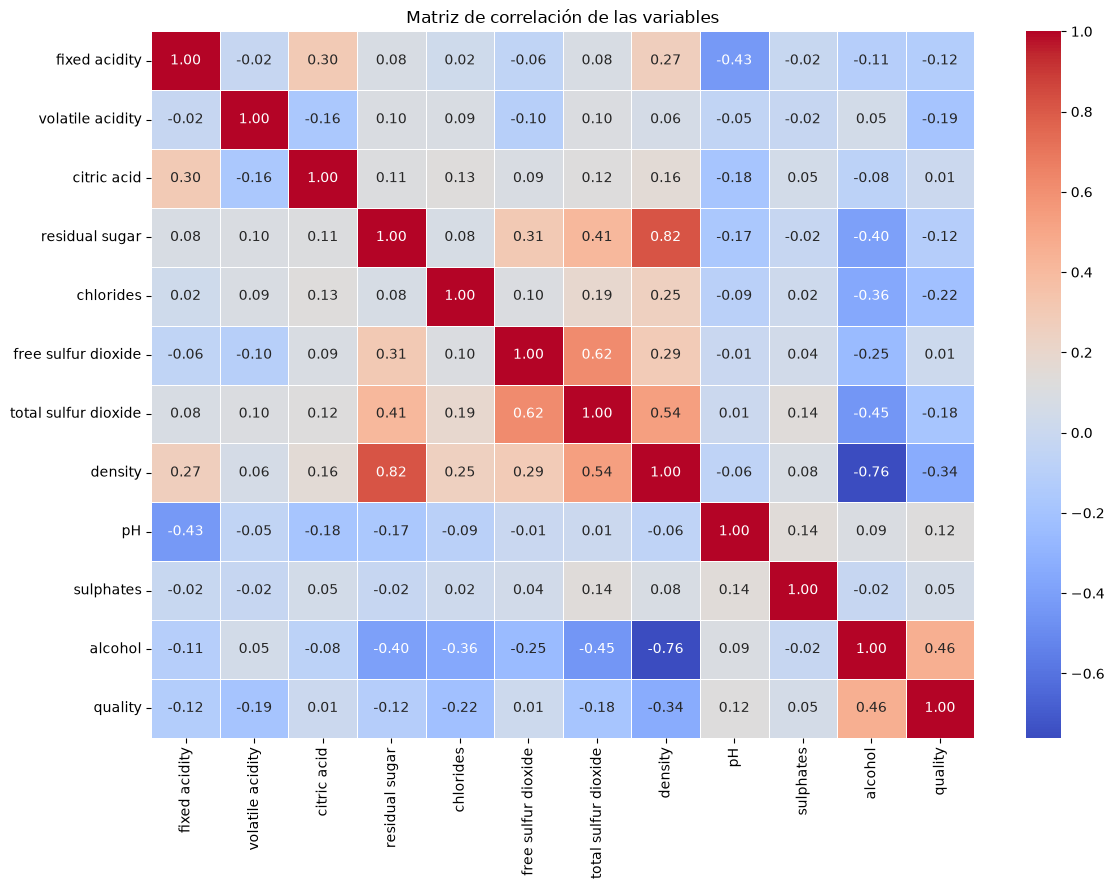

In [53]:
# Calcular la matriz de correlación
correlacion = data.corr()

# Visualizar la matriz de correlación
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlación de las variables")
plt.tight_layout()
plt.show()

**Interpretación de la matriz de correlación:**

El análisis muestra que la variable `alcohol` presenta la mayor correlación positiva con la calidad del vino, con un valor de 0.463. Esto indica que los vinos con mayor graduación alcohólica tienden a presentar mejores puntuaciones de calidad.
Por otro lado, `density` presenta la mayor correlación negativa (-0.34), seguida de `chlorides` (-0.22) y `volatile acidity` (-0.19).
Las demás variables presentan correlaciones débiles o muy cercanas a cero, lo que indica una relación lineal poco significativa con la variable objetivo.

### 5.5. Relación entre las variables fisicoquímicas y la calidad

Se analiza la relación entre las propiedades fisicoquímicas que presentaron mayor correlación con la variable objetivo `quality`, con el propósito de observar cómo se comportan sus valores según los distintos niveles de calidad.

#### Relación entre alcohol y calidad

In [54]:
# Promedio de alcohol según la calidad del vino
data.groupby("quality")["alcohol"].mean()

quality
3    10.345000
4    10.197712
5     9.864182
6    10.646122
7    11.515844
8    11.880153
9    12.180000
Name: alcohol, dtype: float64

**Interpretación:**

Al analizar el promedio de alcohol según los distintos niveles de calidad, se observa una tendencia general creciente. Los vinos con puntuaciones de calidad más elevadas presentan, en promedio, una mayor graduación alcohólica.
Por ejemplo, los vinos de calidad 5 presentan un promedio de 9,86 % de alcohol, mientras que los de calidad 8 y 9 alcanzan promedios de 11,88 % y 12,18 %, respectivamente.
Este comportamiento coincide con la correlación positiva observada anteriormente.

#### Relación entre density y calidad

In [55]:
# Promedio de densidad según la calidad del vino
data.groupby("quality")["density"].mean()

quality
3    0.994884
4    0.994199
5    0.995072
6    0.993722
7    0.992059
8    0.991745
9    0.991460
Name: density, dtype: float64

**Interpretación:**

Al analizar la densidad promedio según los distintos niveles de calidad, se observa una tendencia general decreciente. Los vinos con puntuaciones de calidad más elevadas presentan, en promedio, menores valores de densidad.
Por ejemplo, los vinos de calidad 5 presentan una densidad promedio de 0.995072, mientras que los de calidad 8 y 9 presentan valores de 0.991745 y 0.991460, respectivamente.
Este comportamiento tambien coincide con la correlación negativa observada en la matriz de correlación. Cabe aclarar que, esta relación no implica que la densidad determine por sí sola la calidad del vino.

El análisis exploratorio permitió conocer las características y el comportamiento de las variables que conforman el conjunto de datos utilizado para predecir la calidad del vino blanco. 
En primer lugar, se observó que la variable objetivo `quality` presenta un desbalance en su distribución, ya que la mayor cantidad de registros corresponde a las categorías 5 y 6. 
A través del análisis de las distribuciones y la asimetría, se identificaron diferencias en el comportamiento de las variables fisicoquímicas. También se detectaron posibles valores atípicos en varias de ellas mediante el método del rango intercuartílico (IQR). Estos registros se conservaron inicialmente, debido a que no necesariamente representan errores. 
Por otra parte, el análisis de correlación permitió identificar que `alcohol` presenta la mayor relación positiva con la calidad (0.46), mientras que `density` presenta la mayor relación negativa (-0.34). El análisis de los promedios según los niveles de calidad permitió observar tendencias coherentes con estas relaciones.
A partir de estos resultados, se considera que las propiedades fisicoquímicas contienen información que puede resultar útil para predecir la calidad del vino. Sin embargo, será necesario evaluar el comportamiento de las variables en los modelos de Machine Learning, ya que las correlaciones individuales no determinan por sí solas su capacidad predictiva.

In [56]:
# Verificar las dimensiones del dataset
print("Cantidad de filas y columnas:", data.shape)

# Verificar los tipos de datos
print("\nTipos de datos:")
print(data.dtypes)

# Verificar valores faltantes
print("\nValores faltantes:")
print(data.isnull().sum().sum())

# Verificar duplicados
print("\nCantidad de duplicados:")
print(data.duplicated().sum())

Cantidad de filas y columnas: (3961, 12)

Tipos de datos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Valores faltantes:
0

Cantidad de duplicados:
0


### 6. Preparación de los datos para el modelado

Una vez finalizado el análisis exploratorio, se procede a preparar el conjunto de datos para la aplicación de los algoritmos de aprendizaje automático.
En esta etapa se va a organizar las variables que utilizarán los modelos, se identifica la variable que se desea predecir y se divide el conjunto de datos en entrenamiento y prueba. 

#### 6.1. Separación de variables predictoras y variable objetivo

Para desarrollar los modelos de regresión, se separaron las variables del conjunto de datos en dos grupos:

- **Variables predictoras (X):** incluyen las once propiedades fisicoquímicas del vino blanco.
- **Variable objetivo (y):** corresponde a la columna `quality`, que contiene las puntuaciones de calidad que se buscan predecir.

In [57]:
# Separación de variables predictoras y variable objetivo

X = data.drop(columns=["quality"])
y = data["quality"]

# Verificar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (3961, 11)
Dimensiones de y: (3961,)


#### 6.2. División del conjunto de datos en entrenamiento y prueba

Se destinó el 80 % de las observaciones al conjunto de entrenamiento y el 20 % restante al conjunto de prueba.
El conjunto de entrenamiento será utilizado para que los modelos aprendan las relaciones entre las propiedades fisicoquímicas y la calidad del vino.

In [58]:
from sklearn.model_selection import train_test_split

# División de los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Verificar las dimensiones de cada conjunto

print("X de entrenamiento:", X_train.shape)
print("X de prueba:", X_test.shape)

print("y de entrenamiento:", y_train.shape)
print("y de prueba:", y_test.shape)

X de entrenamiento: (3168, 11)
X de prueba: (793, 11)
y de entrenamiento: (3168,)
y de prueba: (793,)


### Finalización de la preparación de los datos

Una vez realizada la limpieza, el análisis exploratorio y la separación de las variables predictoras y la variable objetivo, se dividió el conjunto de datos en dos subconjuntos: entrenamiento y prueba.

El 80 % de los registros se destinó al entrenamiento y el 20 % restante a la prueba. Esta división permitirá utilizar los datos de entrenamiento para desarrollar los modelos de aprendizaje automático y reservar los datos de prueba para evaluar posteriormente su capacidad predictiva.

De esta manera, el conjunto de datos queda organizado y preparado para continuar con la siguiente etapa del proyecto, correspondiente a la construcción de los modelos de Machine Learning.